In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

data_path = Path("../data/employee_attrition_feature_engineered.csv")

if not data_path.exists():
    data_path = Path("backend/data/employee_attrition_feature_engineered.csv")

df = pd.read_csv(data_path)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (1470, 33)


,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,JobInvolvement,...,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,CompanyExperienceRatio,PromotionFrequency,IncomePerYearExperience,SatisfactionScore,RoleTenureRatio
0,41,Yes,Travel_Rarely,Sales,1,2,Life Sciences,2,Female,3,...,1,6,4,0,5,0.750000,0.000,749.125000,2.00,0.666667
1,49,No,Travel_Frequently,Research & Development,8,1,Life Sciences,3,Male,2,...,3,10,7,1,7,1.000000,0.100,513.000000,3.00,0.700000
2,37,Yes,Travel_Rarely,Research & Development,2,2,Other,4,Male,2,...,3,0,0,0,0,0.000000,0.000,298.571429,3.00,0.000000
3,33,No,Travel_Frequently,Research & Development,3,4,Life Sciences,4,Female,3,...,3,8,7,3,0,1.000000,0.375,363.625000,3.25,0.875000
4,27,No,Travel_Rarely,Research & Development,2,1,Medical,1,Male,3,...,3,2,2,2,2,0.333333,1.000,578.000000,2.50,1.000000


Separate Target

In [3]:
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1470, 32)
Target: (1470,)


Check Numerical Features

In [4]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print(numeric_features)

Number of numerical features: 25
['Age', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'CompanyExperienceRatio', 'PromotionFrequency', 'IncomePerYearExperience', 'SatisfactionScore', 'RoleTenureRatio']


Correlation with Target : Convert Attrition to 0/1

In [5]:
y_numeric = y.map({
    "Yes": 1,
    "No": 0
})

correlation = df[numeric_features].corrwith(y_numeric).sort_values(
    key=abs,
    ascending=False
)

print("Correlation with Attrition:")
print(correlation)

Correlation with Attrition:
TotalWorkingYears          -0.171063
JobLevel                   -0.169105
IncomePerYearExperience     0.169047
YearsInCurrentRole         -0.160545
MonthlyIncome              -0.159840
Age                        -0.159205
SatisfactionScore          -0.159092
YearsWithCurrManager       -0.156199
StockOptionLevel           -0.137145
YearsAtCompany             -0.134392
RoleTenureRatio            -0.130324
JobInvolvement             -0.130016
JobSatisfaction            -0.103481
EnvironmentSatisfaction    -0.103369
DistanceFromHome            0.077924
WorkLifeBalance            -0.063939
TrainingTimesLastYear      -0.059478
RelationshipSatisfaction   -0.045872
NumCompaniesWorked          0.043494
YearsSinceLastPromotion    -0.033019
PromotionFrequency          0.031539
Education                  -0.031373
CompanyExperienceRatio     -0.016244
PercentSalaryHike          -0.013478
PerformanceRating           0.002889
dtype: float64


Visualize Important Correlations

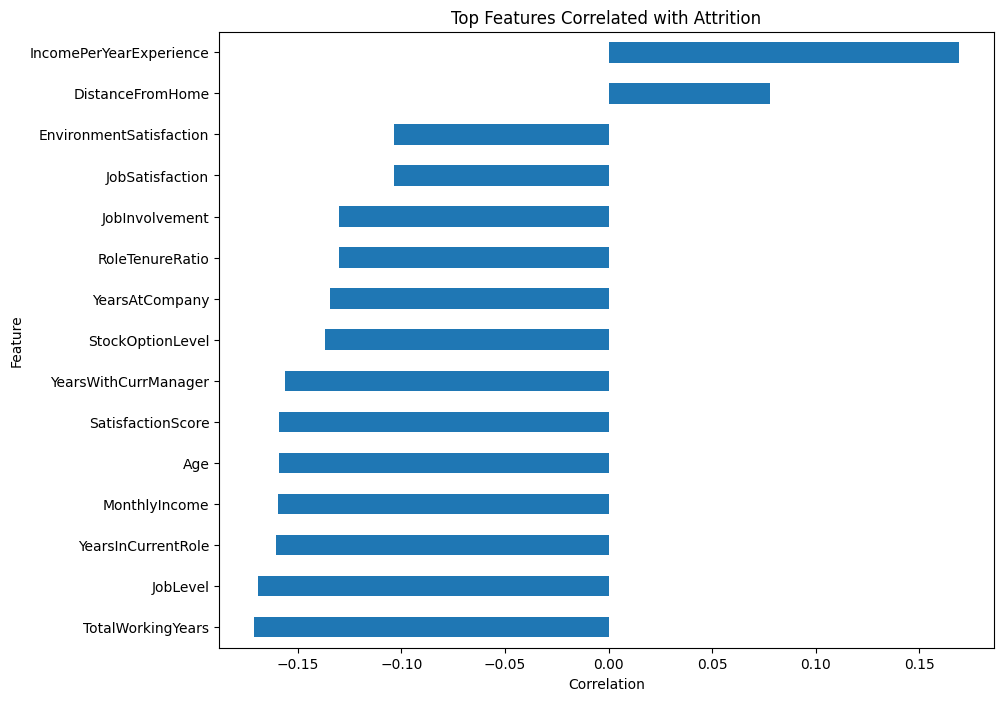

In [6]:
plt.figure(figsize=(10, 8))

correlation.head(15).sort_values().plot(kind="barh")

plt.title("Top Features Correlated with Attrition")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.show()

Check Highly Correlated Features

In [7]:
corr_matrix = X[numeric_features].corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_correlation = []

for column in upper.columns:
    for row in upper.index:
        if upper.loc[row, column] > 0.85:
            high_correlation.append(
                (row, column, upper.loc[row, column])
            )

print("Highly correlated feature pairs:")

if high_correlation:
    for feature1, feature2, value in high_correlation:
        print(f"{feature1} ↔ {feature2}: {value:.2f}")
else:
    print("No highly correlated feature pairs found.")

Highly correlated feature pairs:
JobLevel ↔ MonthlyIncome: 0.95


## Feature Selection: Rank Features Without Automatically Dropping Them

The previous notebook reported every input column as “selected,” so it did not actually perform feature selection. The next cell ranks features using mutual information after one-hot encoding categorical variables.

**Important:** Ranking alone does not prove that removing a feature improves the model. Keep the full feature set until a fair comparison is performed using the same train/test split and cross-validation. Feature selection must be fitted only on training folds to avoid data leakage.

In [8]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

# Encode the target as 0/1.
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y.astype(str))

# One-hot encode categorical predictors for feature ranking only.
X_for_selection = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object", "category"]).columns.tolist(),
    drop_first=False,
    dtype=int
)

# Mutual information can detect non-linear relationships with the target.
mi_scores = mutual_info_classif(
    X_for_selection,
    y_encoded,
    random_state=42
)

feature_ranking = (
    pd.DataFrame({
        "Feature": X_for_selection.columns,
        "Mutual Information": mi_scores
    })
    .sort_values("Mutual Information", ascending=False)
    .reset_index(drop=True)
)

print("Top 20 encoded features by mutual information:")
display(feature_ranking.head(20).round(4))


Top 20 encoded features by mutual information:


,Feature,Mutual Information
0,Age,0.0338
1,OverTime_No,0.0334
2,MonthlyIncome,0.0319
3,TotalWorkingYears,0.0312
4,StockOptionLevel,0.0311
5,OverTime_Yes,0.0304
6,JobRole_Manager,0.0222
7,YearsInCurrentRole,0.0183
8,YearsWithCurrManager,0.0182
9,JobLevel,0.0172


## Final Dataset for Model Training

Do not drop features based only on correlation or mutual-information ranking. The original training pipeline and FastAPI backend expect the original feature names and perform their own preprocessing. This output therefore preserves all predictors while keeping feature-ranking results available for analysis.

To test a reduced feature set, compare it against the baseline using cross-validation inside the training workflow, and keep the reduced set only if it improves the chosen metric consistently.

In [9]:
selected_features = [column for column in df.columns if column != "Attrition"]

selected_df = df[selected_features + ["Attrition"]].copy()

print("Predictors retained:", len(selected_features))
print("Dataset shape:", selected_df.shape)
print("No predictors were removed automatically; the ranking above is diagnostic.")

output_path = data_path.parent / "employee_attrition_selected.csv"
selected_df.to_csv(output_path, index=False)

print("Training dataset saved successfully!")
print("Saved at:", output_path)


Predictors retained: 32
Dataset shape: (1470, 33)
No predictors were removed automatically; the ranking above is diagnostic.
Training dataset saved successfully!
Saved at: ..\data\employee_attrition_selected.csv
